# Actividad 3.1.2 Implementación técnica del proyecto Heart Disease

**Propósito.** Completar el flujo solicitado en la guía: cargar el dataset, explorar clases, preparar datos, comparar modelos, evaluar, generar cinco predicciones y demostrar una automatización por lotes.

**Alcance académico.** La fuente tiene 1.025 filas y 723 duplicados exactos. Se deduplicará antes de la partición para evitar que copias idénticas aparezcan en entrenamiento y prueba; quedan 302 observaciones únicas. Las clases `target=0` y `target=1` se conservan como códigos del archivo. Este ejercicio no es un producto clínico ni permite diagnóstico. Los cinco ejemplos nuevos son sintéticos, no registros de pacientes.

Ejecuta las celdas en orden. En Colab, monta Drive y deja una copia del repositorio (con `data/` y `src/`) bajo `MyDrive/GDPDD`; ajusta `PROJECT_ROOT` si usas otro nombre.

In [1]:
from pathlib import Path
import sys

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = Path('/content/drive/MyDrive/GDPDD')
else:
    PROJECT_ROOT = Path.cwd().resolve()
    if not (PROJECT_ROOT / 'data/raw/heart.csv').exists():
        PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'data/raw/heart.csv').exists():
    raise FileNotFoundError('No se encontró data/raw/heart.csv. Configura PROJECT_ROOT a la carpeta del repositorio.')
sys.path.insert(0, str(PROJECT_ROOT))
try:
    import sklearn
except ImportError:
    %pip install -q -r {PROJECT_ROOT / 'requirements.txt'}
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import xgboost as xgb
from src.modeling import (FEATURES, TARGET, NUMERIC_FEATURES, CATEGORICAL_FEATURES,
                          train_and_evaluate, save_model, predict_batch)
if not xgb.build_info().get('USE_CUDA', False):
    raise RuntimeError('Esta versión de XGBoost no incluye CUDA; no continuar con entrenamiento CPU.')
print('XGBoost:', xgb.__version__, '| CUDA:', xgb.build_info().get('CUDA_VERSION'))
DATA_PATH = PROJECT_ROOT / 'data/raw/heart.csv'
MODEL_PATH = PROJECT_ROOT / 'outputs/models/heart_disease_pipeline.joblib'
OUTPUT_DIR = PROJECT_ROOT / 'outputs/models'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR = PROJECT_ROOT / 'outputs/figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR = PROJECT_ROOT / 'outputs/tables'
TABLES_DIR.mkdir(parents=True, exist_ok=True)
print('Proyecto:', PROJECT_ROOT)
print('Dataset:', DATA_PATH)

XGBoost: 3.2.0 | CUDA: [12, 9]
Proyecto: C:\Users\cesar\OneDrive\Desktop\DuocUC\3erYear\GestionDeProyectoDeDatos\eva1
Dataset: C:\Users\cesar\OneDrive\Desktop\DuocUC\3erYear\GestionDeProyectoDeDatos\eva1\data\raw\heart.csv


## 1. Carga y análisis inicial

In [2]:
df = pd.read_csv(DATA_PATH)
print(f'Dimensiones originales: {df.shape[0]} filas × {df.shape[1]} columnas')
print(f'Filas duplicadas exactas: {df.duplicated().sum()} ({df.duplicated().mean():.1%})')
print('Valores nulos:', int(df.isna().sum().sum()))
print('Columnas:', df.columns.tolist())
display(df.head())
display(df.describe().T)

Dimensiones originales: 1025 filas × 14 columnas
Filas duplicadas exactas: 723 (70.5%)
Valores nulos: 0
Columnas: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.434146,9.072290,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.695610,0.460373,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.942439,1.029641,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.611707,17.516718,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.000000,51.592510,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.149268,0.356527,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.529756,0.527878,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.114146,23.005724,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.336585,0.472772,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.071512,1.175053,0.0,0.0,0.8,1.8,6.2


## 2. Clases y gráficos representativos

El gráfico describe la frecuencia de target en el archivo original y tras deduplicar, que será la base del modelado.

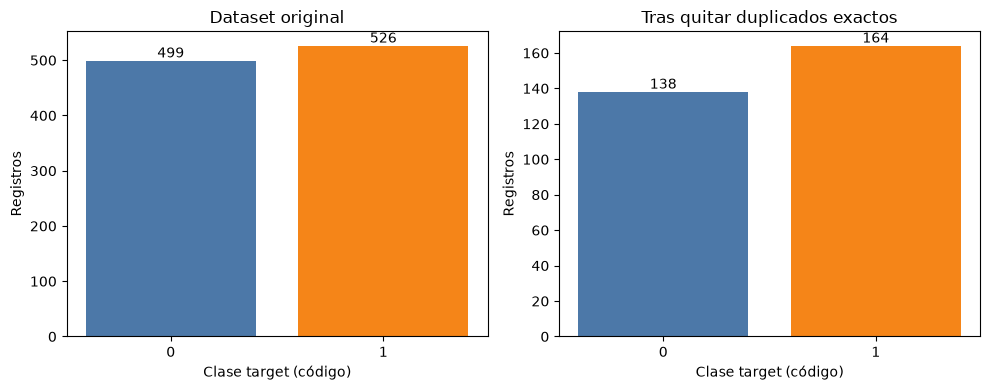

Conteo original:


,registros
target,
0,499
1,526


Conteo deduplicado:


,registros
target,
0,138
1,164


In [3]:
df_unique = df.drop_duplicates().reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, data, title in [(axes[0], df, 'Dataset original'), (axes[1], df_unique, 'Tras quitar duplicados exactos')]:
    counts = data[TARGET].value_counts().sort_index()
    bars = ax.bar(counts.index.astype(str), counts.values, color=['#4C78A8', '#F58518'])
    ax.set(title=title, xlabel='Clase target (código)', ylabel='Registros')
    ax.bar_label(bars)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'distribucion_clases_antes_despues_deduplicar.png', dpi=180, bbox_inches='tight')
plt.show()
print('Conteo original:')
display(df[TARGET].value_counts().sort_index().rename('registros').to_frame())
print('Conteo deduplicado:')
display(df_unique[TARGET].value_counts().sort_index().rename('registros').to_frame())

## 3. Diagnóstico de correlación, categorías y valores extremos

La matriz de Pearson se limita a variables cuantitativas y `target`; los códigos categóricos no se interpretan como medidas continuas. Para las categorías se calcula una asociación descriptiva entre cada nivel y la clase (correlación de una indicadora binaria con target). Ninguna de estas asociaciones prueba causalidad ni justifica eliminar variables por sí sola.

Los diagramas de caja identifican valores fuera de la regla exploratoria de 1,5×IQR. Esa regla es una señal para revisar, no un criterio automático de error. Se conservan los valores extremos si no hay evidencia de que sean inválidos.

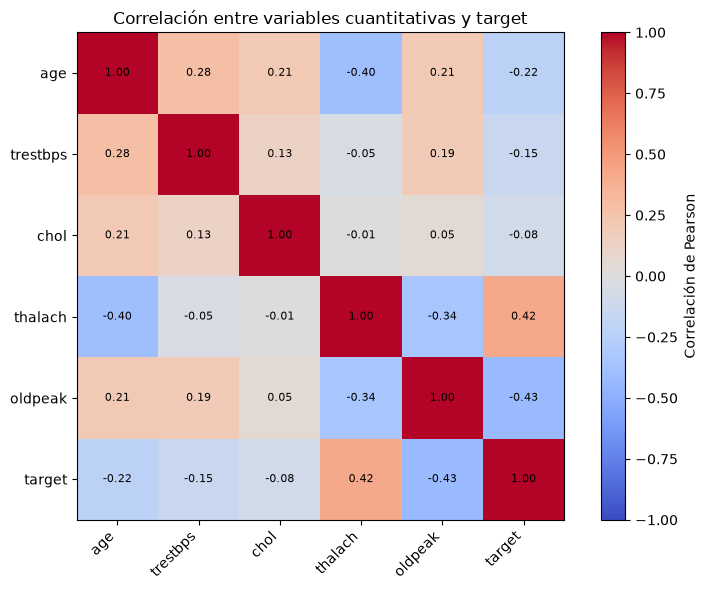

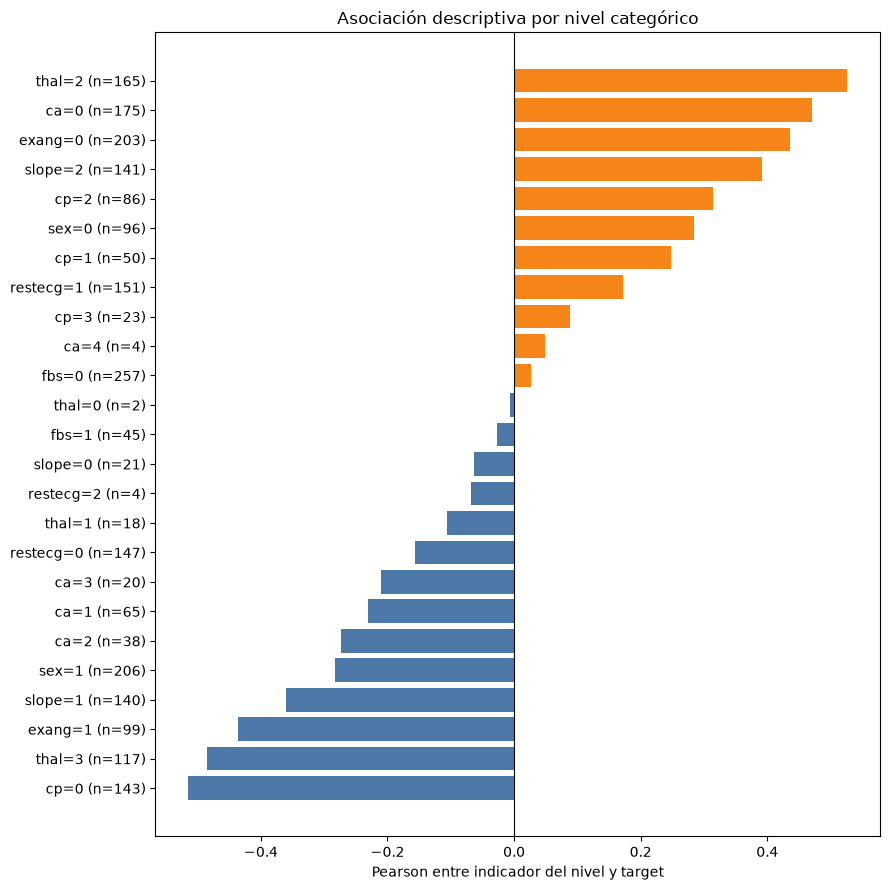

,variable,min,max,limite_inferior_iqr,limite_superior_iqr,conteo_fuera_iqr
0,age,29.0,77.0,28.500,80.500,0
1,trestbps,94.0,200.0,90.000,170.000,9
2,chol,126.0,564.0,115.375,370.375,5
3,thalach,71.0,202.0,84.125,215.125,1
4,oldpeak,0.0,6.2,-2.400,4.000,5


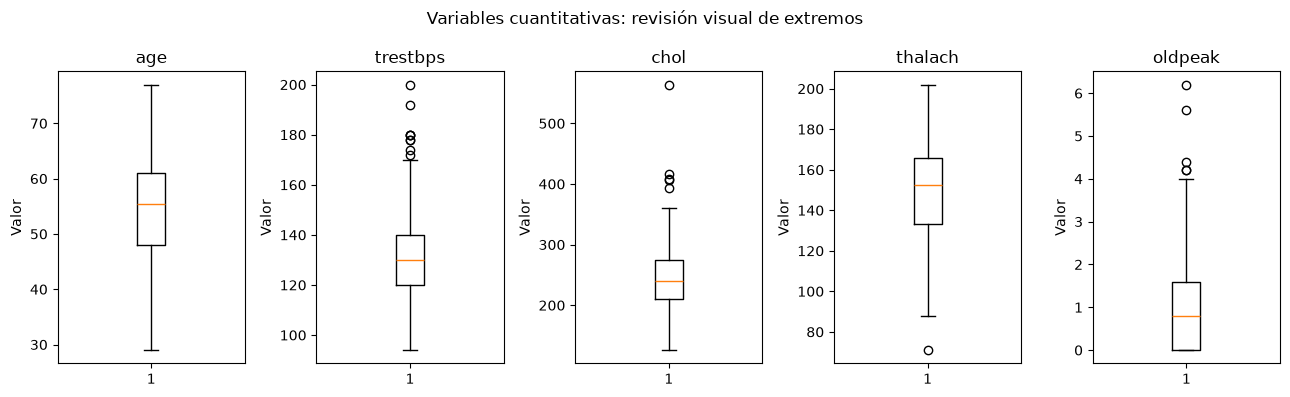

Gráficos y tablas guardados en C:\Users\cesar\OneDrive\Desktop\DuocUC\3erYear\GestionDeProyectoDeDatos\eva1\outputs\figures y C:\Users\cesar\OneDrive\Desktop\DuocUC\3erYear\GestionDeProyectoDeDatos\eva1\outputs\tables


In [4]:
# Correlación de Pearson solo entre variables cuantitativas y target binario.
pearson_corr = df_unique[NUMERIC_FEATURES + [TARGET]].corr(method='pearson')
pearson_corr.to_csv(TABLES_DIR / 'correlacion_pearson_continuas_target.csv')
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(pearson_corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(pearson_corr.columns)), pearson_corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(pearson_corr.index)), pearson_corr.index)
for row in range(len(pearson_corr.index)):
    for col in range(len(pearson_corr.columns)):
        ax.text(col, row, f'{pearson_corr.iloc[row, col]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(image, ax=ax, label='Correlación de Pearson')
ax.set_title('Correlación entre variables cuantitativas y target')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'matriz_correlacion_continuas_target.png', dpi=180, bbox_inches='tight')
plt.show()

# Asociación univariada de cada nivel categórico con target (indicadora binaria).
association_rows = []
for feature in CATEGORICAL_FEATURES:
    for value in sorted(df_unique[feature].dropna().unique()):
        indicator = df_unique[feature].eq(value).astype(int)
        association_rows.append({
            'nivel': f'{feature}={value} (n={int(indicator.sum())})',
            'variable': feature,
            'categoria': value,
            'n': int(indicator.sum()),
            'correlacion_indicadora_target': indicator.corr(df_unique[TARGET]),
        })
category_association = pd.DataFrame(association_rows).dropna().sort_values(
    'correlacion_indicadora_target'
)
category_association.to_csv(TABLES_DIR / 'asociacion_niveles_categoricos_target.csv', index=False)
fig, ax = plt.subplots(figsize=(9, 9))
colors = ['#4C78A8' if value < 0 else '#F58518' for value in category_association['correlacion_indicadora_target']]
ax.barh(category_association['nivel'], category_association['correlacion_indicadora_target'], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set(xlabel='Pearson entre indicador del nivel y target', title='Asociación descriptiva por nivel categórico')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'asociacion_niveles_categoricos_target.png', dpi=180, bbox_inches='tight')
plt.show()

# Auditoría IQR sin recortar ni eliminar filas.
rows = []
for feature in NUMERIC_FEATURES:
    q1, q3 = df_unique[feature].quantile([0.25, 0.75])
    lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    rows.append({'variable': feature, 'min': df_unique[feature].min(), 'max': df_unique[feature].max(),
                 'limite_inferior_iqr': lower, 'limite_superior_iqr': upper,
                 'conteo_fuera_iqr': int(((df_unique[feature] < lower) | (df_unique[feature] > upper)).sum())})
iqr_audit = pd.DataFrame(rows)
iqr_audit.to_csv(TABLES_DIR / 'auditoria_extremos_iqr.csv', index=False)
display(iqr_audit)
fig, axes = plt.subplots(1, len(NUMERIC_FEATURES), figsize=(13, 4))
for ax, feature in zip(axes, NUMERIC_FEATURES):
    ax.boxplot(df_unique[feature], showfliers=True)
    ax.set_title(feature)
    ax.set_ylabel('Valor')
fig.suptitle('Variables cuantitativas: revisión visual de extremos')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'diagramas_caja_variables_cuantitativas.png', dpi=180, bbox_inches='tight')
plt.show()
print('Gráficos y tablas guardados en', FIGURES_DIR, 'y', TABLES_DIR)

## 4. Preparación y decisiones de limpieza

La fuente no tiene nulos. Hay 723 duplicados exactos, por eso se quitan antes de la partición; no se recortan por IQR los valores extremos sin evidencia de error. El diccionario del proyecto registra dominios que difieren de UCI en `cp`, `slope`, `ca` y `thal` (incluye `ca=4`); se preservan los valores observados y no se inventan recodificaciones. Al no conocerse la semántica exacta de esta copia, esas variables discretas se tratan como categóricas nominales mediante one-hot, en vez de imponer distancias numéricas entre códigos.

Para la regresión logística, las variables cuantitativas se escalan con `RobustScaler` y las categóricas se codifican dentro del pipeline. XGBoost recibe las cuantitativas sin escalar (los árboles parten por umbrales) y las categóricas one-hot. Todo preprocesamiento se aprende dentro de cada fold para evitar fuga. No se eliminan predictores por correlación: la matriz es exploratoria y no muestra redundancia suficiente para justificar perder señales.

In [5]:
assert set(FEATURES + [TARGET]) == set(df.columns), 'El esquema del dataset cambió.'
assert not df[FEATURES + [TARGET]].isna().any().any(), 'Hay nulos que requieren tratamiento documentado.'
print('Variable dependiente:', TARGET)
print('Variables independientes:', FEATURES)
print(f'Registros para modelado: {len(df_unique)}; descartados por duplicado exacto: {len(df)-len(df_unique)}')
print('Clases disponibles:', sorted(df_unique[TARGET].unique().tolist()))
feature_label_groups = df.groupby(FEATURES, dropna=False)[TARGET].nunique()
label_conflicts = int((feature_label_groups > 1).sum())
print('Combinaciones predictoras repetidas:', len(df) - len(feature_label_groups))
print('Combinaciones predictoras con target contradictorio:', label_conflicts)
assert label_conflicts == 0, 'Revisar filas idénticas en predictores con etiquetas distintas.'

Variable dependiente: target
Variables independientes: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
Registros para modelado: 302; descartados por duplicado exacto: 723
Clases disponibles: [0, 1]
Combinaciones predictoras repetidas: 723
Combinaciones predictoras con target contradictorio: 0


## 5. Partición de entrenamiento y prueba

Se usa una partición estratificada 75/25 con semilla fija. El escalado forma parte del pipeline y se ajusta sólo dentro de cada partición de entrenamiento.

In [6]:
result = train_and_evaluate(df)
print('Train:', result['X_train'].shape, '| Test:', result['X_test'].shape)
print('Target train:', result['y_train'].value_counts().sort_index().to_dict())
print('Target test:', result['y_test'].value_counts().sort_index().to_dict())

C:\Users\cesar\OneDrive\Desktop\DuocUC\3erYear\GestionDeProyectoDeDatos\eva1\.venv\Lib\site-packages\xgboost\core.py:751: UserWarning: [23:08:27] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


Train: (226, 13) | Test: (76, 13)
Target train: {0: 103, 1: 123}
Target test: {0: 35, 1: 41}


## 6. Entrenamiento y selección de modelo

Se compara el modelo previo (códigos categóricos tratados como ordinales) contra pipelines con codificación one-hot; la regresión logística incluye RobustScaler como referencia CPU. La selección final se hace por ROC-AUC promedio en validación cruzada estratificada de cinco folds, restringida a los candidatos XGBoost one-hot en CUDA. El test queda apartado para evaluación final. Si CUDA no está disponible, XGBoost falla en vez de cambiar silenciosamente a CPU.

,modelo,dispositivo,preparación,roc_auc_cv_promedio,roc_auc_cv_desv
0,"Regresión logística (RobustScaler + one-hot, CPU)",CPU,One-hot + RobustScaler numérico,0.919,0.052
1,XGBoost CUDA (baseline ordinal previo),CUDA GPU,Códigos originales como ordinales (pipeline previo),0.917,0.062
2,XGBoost CUDA (one-hot somero),CUDA GPU,Categóricas one-hot,0.914,0.055
3,XGBoost CUDA (one-hot regularizado),CUDA GPU,Categóricas one-hot,0.913,0.061


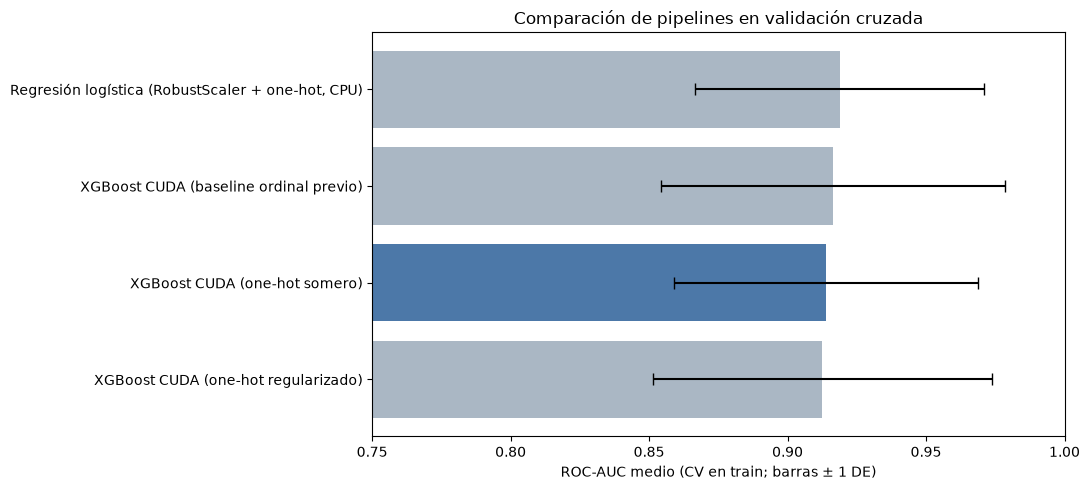

Modelo seleccionado por ROC-AUC CV: XGBoost CUDA (one-hot somero)
La elección es un baseline educativo; no implica que los controles de datos o clínicos estén completos.


In [7]:
comparison = result['comparison'].copy()
comparison.to_csv(TABLES_DIR / 'comparacion_modelos_validacion_cruzada.csv', index=False)
display(comparison.style.format({'roc_auc_cv_promedio': '{:.3f}', 'roc_auc_cv_desv': '{:.3f}'}))
cv_plot = comparison.iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(cv_plot['modelo'], cv_plot['roc_auc_cv_promedio'],
        xerr=cv_plot['roc_auc_cv_desv'], capsize=4,
        color=['#4C78A8' if name == result['selected_name'] else '#AAB7C4'
               for name in cv_plot['modelo']])
ax.set_xlabel('ROC-AUC medio (CV en train; barras ± 1 DE)')
ax.set_xlim(0.75, 1.0)
ax.set_title('Comparación de pipelines en validación cruzada')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'comparacion_roc_auc_validacion_cruzada.png', dpi=180, bbox_inches='tight')
plt.show()
print('Modelo seleccionado por ROC-AUC CV:', result['selected_name'])
print('La elección es un baseline educativo; no implica que los controles de datos o clínicos estén completos.')

## 7. Evaluación final en test

Se comparan las métricas del pipeline previo y del nuevo pipeline en el mismo test retenido. Esta comparación estima el efecto de codificar categóricas como nominales; la selección del modelo final se hizo antes, por validación cruzada en train. Las métricas no tienen interpretación clínica demostrada.

,Pipeline previo (ordinal),Pipeline nuevo (one-hot)
accuracy,0.789,0.776
precision_clase_1,0.791,0.786
recall_clase_1,0.829,0.805
f1_clase_1,0.810,0.795
roc_auc,0.875,0.875


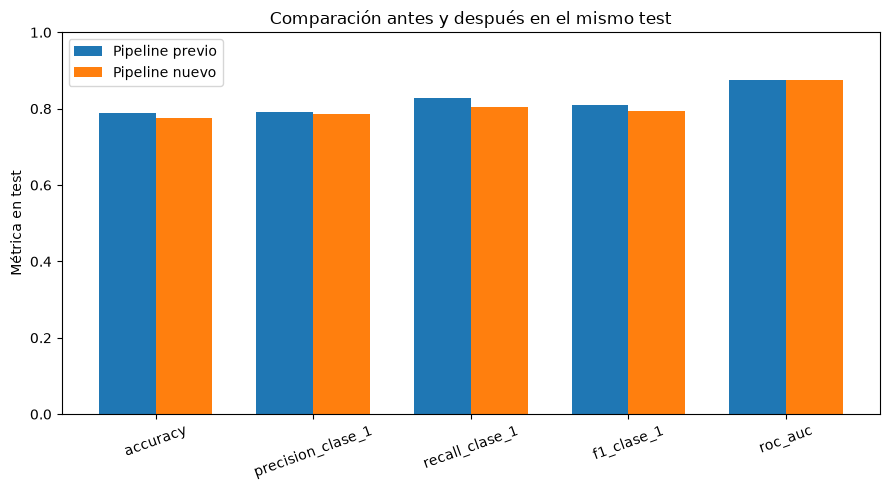

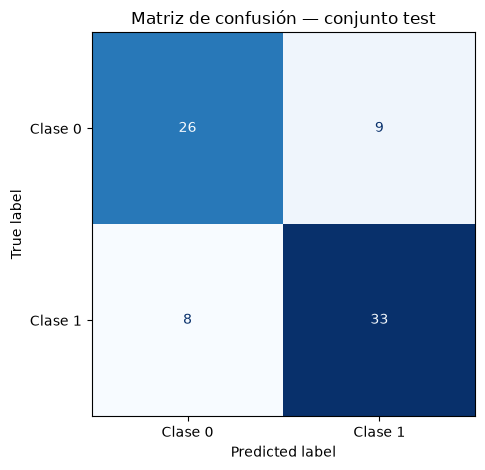

No existe un umbral clínico validado ni garantía de sensibilidad adecuada para uso sanitario.


In [8]:
from sklearn.metrics import ConfusionMatrixDisplay
metrics = pd.DataFrame({
    'Pipeline previo (ordinal)': result['baseline_metrics'],
    'Pipeline nuevo (one-hot)': result['metrics'],
})
metrics.to_csv(TABLES_DIR / 'comparacion_metricas_test_antes_despues.csv')
display(metrics.style.format('{:.3f}'))
fig, ax = plt.subplots(figsize=(9, 5))
positions = np.arange(len(metrics.index))
width = 0.36
ax.bar(positions - width/2, metrics.iloc[:, 0], width, label='Pipeline previo')
ax.bar(positions + width/2, metrics.iloc[:, 1], width, label='Pipeline nuevo')
ax.set_xticks(positions, metrics.index, rotation=20)
ax.set_ylim(0, 1)
ax.set_ylabel('Métrica en test')
ax.set_title('Comparación antes y después en el mismo test')
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'comparacion_metricas_test_antes_despues.png', dpi=180, bbox_inches='tight')
plt.show()
ConfusionMatrixDisplay.from_predictions(
    result['y_test'], result['predictions'], labels=[0, 1],
    display_labels=['Clase 0', 'Clase 1'], cmap='Blues', colorbar=False
)
plt.title('Matriz de confusión — conjunto test')
plt.tight_layout()
plt.show()
print('No existe un umbral clínico validado ni garantía de sensibilidad adecuada para uso sanitario.')

## 8. Cinco predicciones con nuevos datos sintéticos

Las cinco entradas son ejemplos sintéticos dentro de rangos observados; no representan individuos. El score para clase 1 no está calibrado y no debe interpretarse como riesgo clínico.

In [9]:
SAMPLE_PATH = PROJECT_ROOT / 'data/samples/predicciones_ejemplo.csv'
new_data = pd.read_csv(SAMPLE_PATH)
assert new_data.shape == (5, len(FEATURES))
artifact_path = save_model(result['model'], MODEL_PATH)
print('Artefacto del pipeline:', artifact_path)
display(predict_batch(new_data, artifact_path))

Artefacto del pipeline: C:\Users\cesar\OneDrive\Desktop\DuocUC\3erYear\GestionDeProyectoDeDatos\eva1\outputs\models\heart_disease_pipeline.joblib


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,prediction_class,score_class_1_uncalibrated
0,52,1,0,125,212,0,1,168,0,1.0,1,0,2,1,0.801189
1,61,0,2,140,250,0,0,150,1,2.3,1,1,3,0,0.267867
2,45,1,1,130,233,0,1,179,0,0.4,2,0,2,1,0.978634
3,68,1,0,170,284,1,2,132,1,3.0,0,2,3,0,0.011948
4,57,0,3,120,354,0,1,163,0,0.6,2,0,2,1,0.975111


## 9. Automatización propuesta e implementada

**Propuesta:** procesar un CSV mediante un comando batch. El flujo valida las 13 columnas esperadas, su orden y los nulos; carga el pipeline fijado (entrenado en CUDA), genera la clase y un score y guarda un CSV con marca temporal. Reduce preparación manual y conserva una salida trazable. No reentrena ni publica un modelo automáticamente; una actualización requiere evaluación y aprobación explícitas.

El siguiente paso ejecuta la función automatizada sobre el lote de cinco ejemplos. El CLI equivalente se puede correr desde la raíz:

```powershell
python src/automatizacion_predicciones.py data/samples/predicciones_ejemplo.csv outputs/models/heart_disease_pipeline.joblib outputs/predicciones_ejemplo.csv
```

In [10]:
from src.modeling import predict_batch
from datetime import datetime, timezone
automation_output = predict_batch(new_data, artifact_path)
automation_output.insert(0, 'generated_at_utc', datetime.now(timezone.utc).isoformat(timespec='seconds'))
CSV_OUTPUT = PROJECT_ROOT / 'outputs/models/predicciones_ejemplo.csv'
automation_output.to_csv(CSV_OUTPUT, index=False)
print(f'Lote validado y procesado: {len(automation_output)} filas')
print(f'CSV generado: {CSV_OUTPUT}')
display(automation_output[['prediction_class', 'score_class_1_uncalibrated']])

Lote validado y procesado: 5 filas
CSV generado: C:\Users\cesar\OneDrive\Desktop\DuocUC\3erYear\GestionDeProyectoDeDatos\eva1\outputs\models\predicciones_ejemplo.csv


,prediction_class,score_class_1_uncalibrated
0,1,0.801189
1,0,0.267867
2,1,0.978634
3,0,0.011948
4,1,0.975111


## Reflexión grupal propuesta

Para este proyecto, el componente con mayor impacto en el éxito del negocio sería **la forma de comunicar los resultados**. El modelo produce una señal, pero sus métricas dependen de una muestra pequeña, duplicados y una semántica de etiqueta y representatividad aún por validar. La automatización aporta consistencia, aunque también puede propagar errores si opera sin controles. Comunicar qué significa la salida, qué evidencia la respalda y cuáles son sus límites ayuda a evitar que una clasificación educativa se interprete como diagnóstico. Esta respuesta queda como propuesta para revisión grupal.

## Cierre y límites

El flujo completa una demostración reproducible de carga, exploración, preparación, entrenamiento, selección, evaluación, inferencia y automatización. Antes de cualquier uso externo al ejercicio académico se debe verificar procedencia y semántica de `target`, calidad y representatividad del dato, calibración, desempeño por subgrupos, privacidad, seguridad y aceptación experta. El informe 3.2.2 describe una simulación de gestión; sus estados y pronósticos no son evidencia de que este modelo haya sido desplegado o aceptado.